# Financial Plots - Main

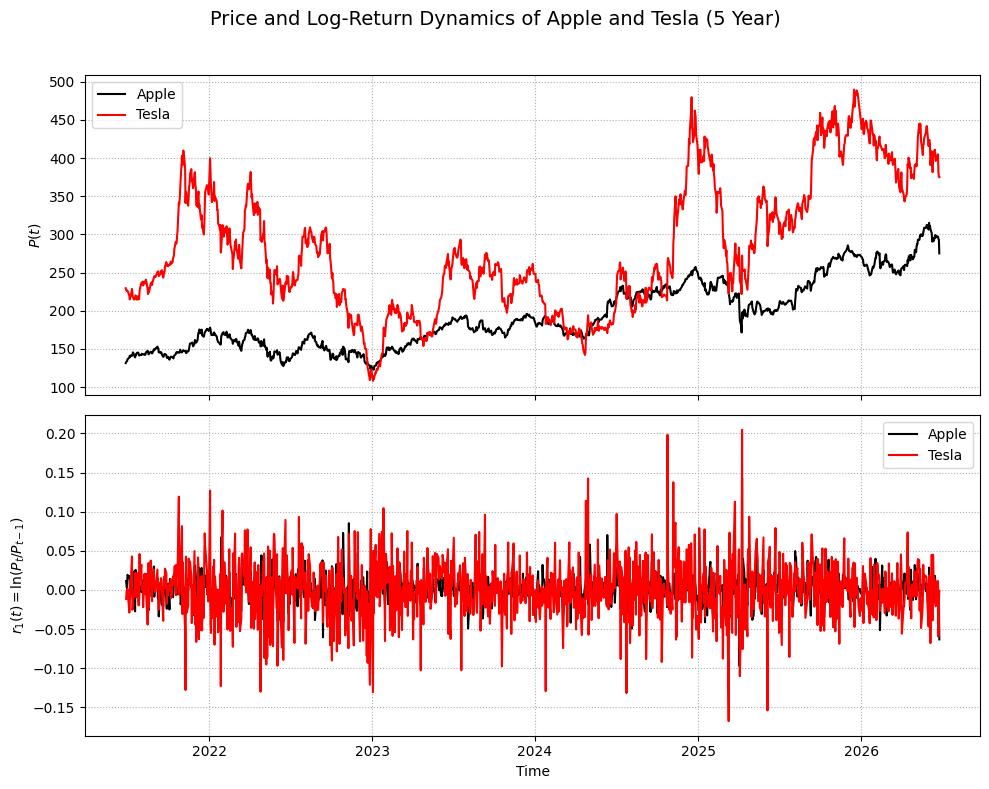

In [7]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

tickers = {
    "Apple": "AAPL",
    "Tesla": "TSLA"
}

colors = {
    "Apple": "black",
    "Tesla": "red"
}

data = {
    name: yf.download(ticker, period="5y", auto_adjust=True, progress=False)
    for name, ticker in tickers.items()
}

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

fig.suptitle("Price and Log-Return Dynamics of Apple and Tesla (5 Year)", fontsize=14)

for name, df in data.items():
    p = df["Close"].squeeze().dropna()
    r1 = np.log(p / p.shift(1)).dropna()

    ax1.plot(p.index, p, color=colors[name], label=name)
    ax2.plot(r1.index, r1, color=colors[name], label=name)

ax1.set_ylabel(r"$P(t)$")
ax1.legend()
ax1.grid(True, linestyle=":")

ax2.set_ylabel(r"$r_1(t)=\ln(P_t/P_{t-1})$")
ax2.set_xlabel("Time")
ax2.legend()
ax2.grid(True, linestyle=":")

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [8]:
# ============================================================
# Summary Statistics & Stylized Facts Tests
# ============================================================

import pandas as pd
import numpy as np

from scipy.stats import (
    skew,
    kurtosis,
    jarque_bera,
    kstest,
    norm
)

from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import (
    acorr_ljungbox,
    het_arch
)

results = []

for name, df in data.items():

    price = df["Close"].squeeze().dropna()
    returns = np.log(price / price.shift(1)).dropna()

    # Standardize for KS test
    z = (returns - returns.mean()) / returns.std()

    # Statistics
    mean = returns.mean()
    std = returns.std()
    skewness = skew(returns)
    ex_kurt = kurtosis(returns, fisher=True)

    # Normality
    jb_stat, jb_p = jarque_bera(returns)
    ks_stat, ks_p = kstest(z, "norm")

    # Stationarity
    adf_stat, adf_p, *_ = adfuller(returns)

    # Linear autocorrelation
    lb = acorr_ljungbox(
        returns,
        lags=[20],
        return_df=True
    )

    lb_stat = lb["lb_stat"].iloc[0]
    lb_p = lb["lb_pvalue"].iloc[0]

    # Volatility clustering (ARCH effect)
    arch_stat, arch_p, _, _ = het_arch(returns)

    results.append({

        "Asset": name,

        "Mean": mean,
        "Std": std,

        "Skewness": skewness,
        "Excess Kurtosis": ex_kurt,

        "Jarque-Bera p": jb_p,
        "KS p": ks_p,

        "ADF p": adf_p,

        "Ljung-Box(20) p": lb_p,

        "ARCH-LM p": arch_p
    })

summary = pd.DataFrame(results)

pd.set_option("display.float_format", "{:.5f}".format)

display(summary)

,Asset,Mean,Std,Skewness,Excess Kurtosis,Jarque-Bera p,KS p,ADF p,Ljung-Box(20) p,ARCH-LM p
0,Apple,0.00059,0.01737,0.21299,5.82319,0.00000,0.00002,0.00000,0.54699,0.00000
1,Tesla,0.00039,0.03707,0.03158,2.62722,0.00000,0.00788,0.00000,0.22574,0.00001


,Asset,N,Mean,Std,Skewness,Excess Kurtosis,JB Stat,JB p,KS Stat,KS p,...,Ljung-Box(20) Stat,Ljung-Box(20) p,ARCH-LM(20) Stat,ARCH-LM(20) p,ACF r lag 1,ACF r lag 5,ACF r lag 20,ACF |r| lag 1,ACF |r| lag 5,ACF |r| lag 20
0,Apple,1253,0.00059,0.01737,0.21299,5.82319,1779.83612,0.00000,0.06785,0.00002,...,18.61455,0.54699,140.76538,0.00000,0.02274,0.00069,0.03216,0.20482,0.14194,0.10573
1,Tesla,1253,0.00039,0.03707,0.03158,2.62722,360.56500,0.00000,0.04686,0.00788,...,24.39064,0.22574,55.89869,0.00003,-0.01615,-0.00266,0.03178,0.03623,0.02556,0.04160


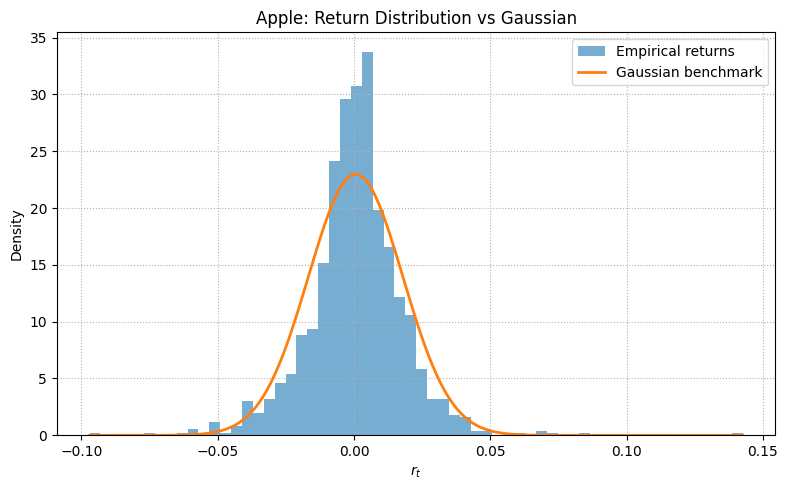

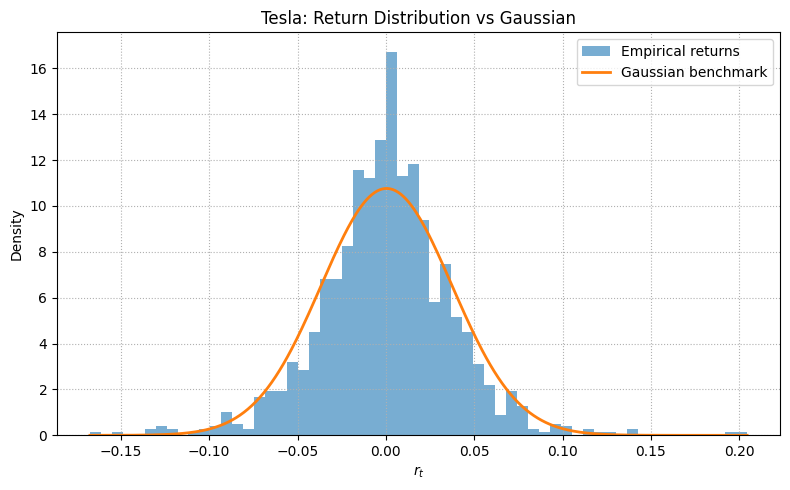

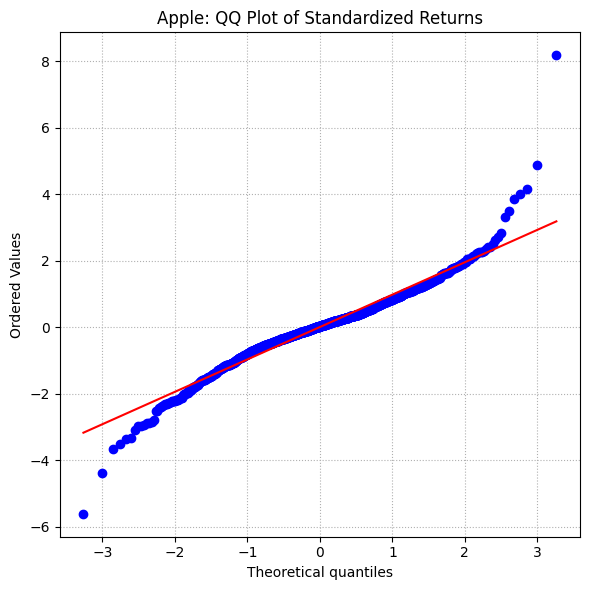

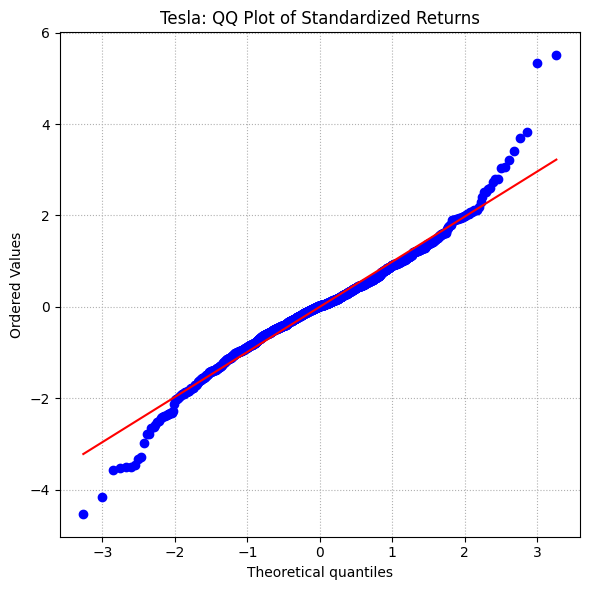

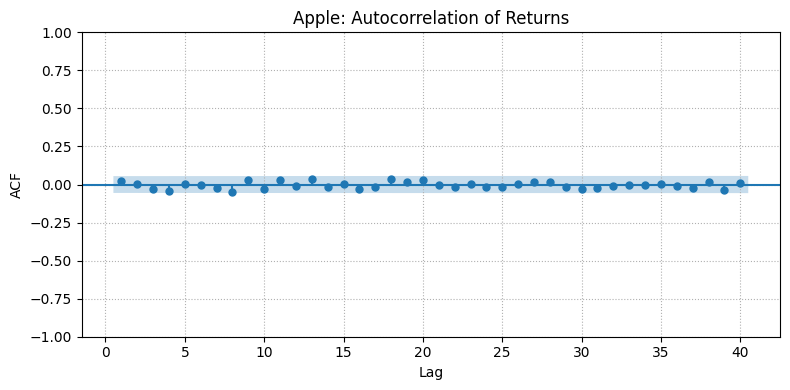

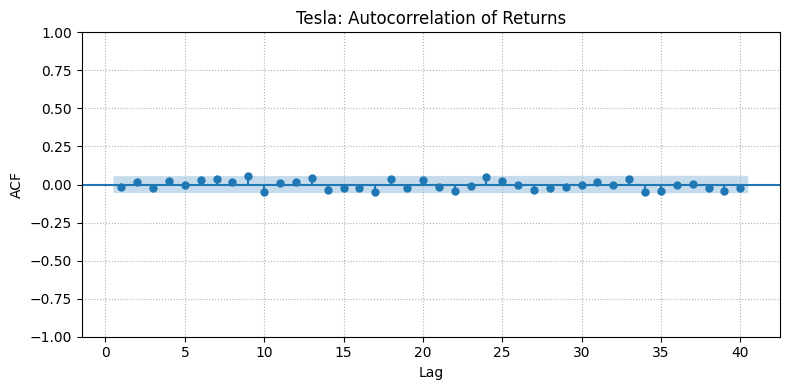

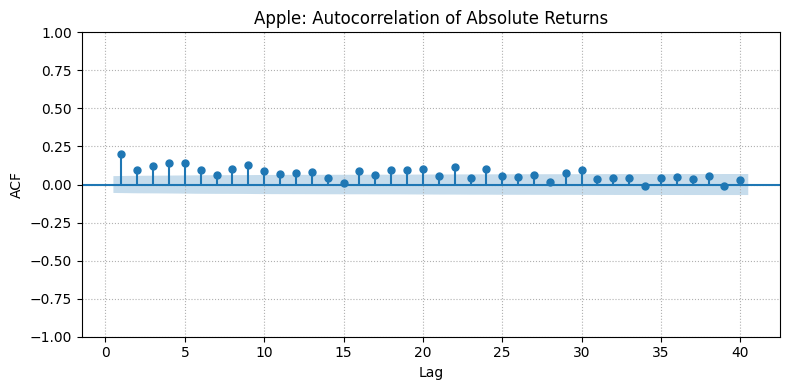

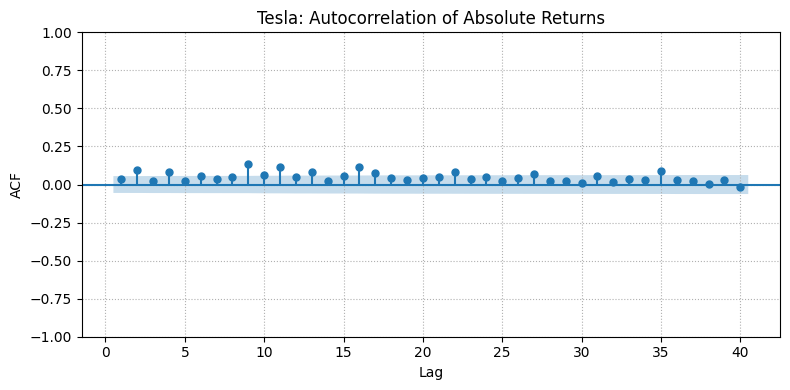

In [9]:
# ============================================================
# Summary Statistics, Stylized Facts Tests, and Diagnostic Plots
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import (
    skew,
    kurtosis,
    jarque_bera,
    kstest,
    norm,
    probplot
)

from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf


# ------------------------------------------------------------
# Helper: return series
# ------------------------------------------------------------
def get_log_returns(df):
    price = df["Close"].squeeze().dropna()
    returns = np.log(price / price.shift(1)).dropna()
    return returns


# ------------------------------------------------------------
# 1. Statistical summary table
# ------------------------------------------------------------
results = []

for name, df in data.items():

    returns = get_log_returns(df)
    z = (returns - returns.mean()) / returns.std()

    # Basic statistics
    mean = returns.mean()
    std = returns.std()
    skewness = skew(returns)
    ex_kurt = kurtosis(returns, fisher=True)

    # Normality tests
    jb_stat, jb_p = jarque_bera(returns)
    ks_stat, ks_p = kstest(z, "norm")

    # Stationarity test
    adf_stat, adf_p, *_ = adfuller(returns)

    # Linear autocorrelation test
    lb = acorr_ljungbox(returns, lags=[20], return_df=True)
    lb_stat = lb["lb_stat"].iloc[0]
    lb_p = lb["lb_pvalue"].iloc[0]

    # ARCH effect / volatility clustering test
    arch_stat, arch_p, _, _ = het_arch(returns, nlags=20)

    # Direct autocorrelation values
    acf_r_1 = returns.autocorr(lag=1)
    acf_r_5 = returns.autocorr(lag=5)
    acf_r_20 = returns.autocorr(lag=20)

    abs_returns = np.abs(returns)
    acf_abs_1 = abs_returns.autocorr(lag=1)
    acf_abs_5 = abs_returns.autocorr(lag=5)
    acf_abs_20 = abs_returns.autocorr(lag=20)

    results.append({
        "Asset": name,
        "N": len(returns),

        "Mean": mean,
        "Std": std,
        "Skewness": skewness,
        "Excess Kurtosis": ex_kurt,

        "JB Stat": jb_stat,
        "JB p": jb_p,

        "KS Stat": ks_stat,
        "KS p": ks_p,

        "ADF Stat": adf_stat,
        "ADF p": adf_p,

        "Ljung-Box(20) Stat": lb_stat,
        "Ljung-Box(20) p": lb_p,

        "ARCH-LM(20) Stat": arch_stat,
        "ARCH-LM(20) p": arch_p,

        "ACF r lag 1": acf_r_1,
        "ACF r lag 5": acf_r_5,
        "ACF r lag 20": acf_r_20,

        "ACF |r| lag 1": acf_abs_1,
        "ACF |r| lag 5": acf_abs_5,
        "ACF |r| lag 20": acf_abs_20,
    })

summary = pd.DataFrame(results)

pd.set_option("display.float_format", "{:.5f}".format)

display(summary)


# ------------------------------------------------------------
# 2. Histogram with Gaussian overlay
# ------------------------------------------------------------
for name, df in data.items():

    returns = get_log_returns(df)

    mu = returns.mean()
    sigma = returns.std()

    x = np.linspace(returns.min(), returns.max(), 500)
    gaussian_pdf = norm.pdf(x, mu, sigma)

    plt.figure(figsize=(8, 5))

    plt.hist(
        returns,
        bins=60,
        density=True,
        alpha=0.6,
        label="Empirical returns"
    )

    plt.plot(
        x,
        gaussian_pdf,
        linewidth=2,
        label="Gaussian benchmark"
    )

    plt.title(f"{name}: Return Distribution vs Gaussian")
    plt.xlabel(r"$r_t$")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, linestyle=":")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 3. QQ plots
# ------------------------------------------------------------
for name, df in data.items():

    returns = get_log_returns(df)
    z = (returns - returns.mean()) / returns.std()

    plt.figure(figsize=(6, 6))
    probplot(z, dist="norm", plot=plt)

    plt.title(f"{name}: QQ Plot of Standardized Returns")
    plt.grid(True, linestyle=":")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 4. ACF of returns
# ------------------------------------------------------------
for name, df in data.items():

    returns = get_log_returns(df)

    fig, ax = plt.subplots(figsize=(8, 4))
    plot_acf(
        returns,
        lags=40,
        ax=ax,
        alpha=0.05,
        zero=False
    )

    ax.set_title(f"{name}: Autocorrelation of Returns")
    ax.set_xlabel("Lag")
    ax.set_ylabel("ACF")
    ax.grid(True, linestyle=":")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 5. ACF of absolute returns
# ------------------------------------------------------------
for name, df in data.items():

    returns = get_log_returns(df)
    abs_returns = np.abs(returns)

    fig, ax = plt.subplots(figsize=(8, 4))
    plot_acf(
        abs_returns,
        lags=40,
        ax=ax,
        alpha=0.05,
        zero=False
    )

    ax.set_title(f"{name}: Autocorrelation of Absolute Returns")
    ax.set_xlabel("Lag")
    ax.set_ylabel("ACF")
    ax.grid(True, linestyle=":")
    plt.tight_layout()
    plt.show()


Apple
Excess kurtosis: 6.715
Jarque-Bera p-value: 0
KS p-value: 6.244e-15

Tesla
Excess kurtosis: 4.231
Jarque-Bera p-value: 0
KS p-value: 1.2909e-08


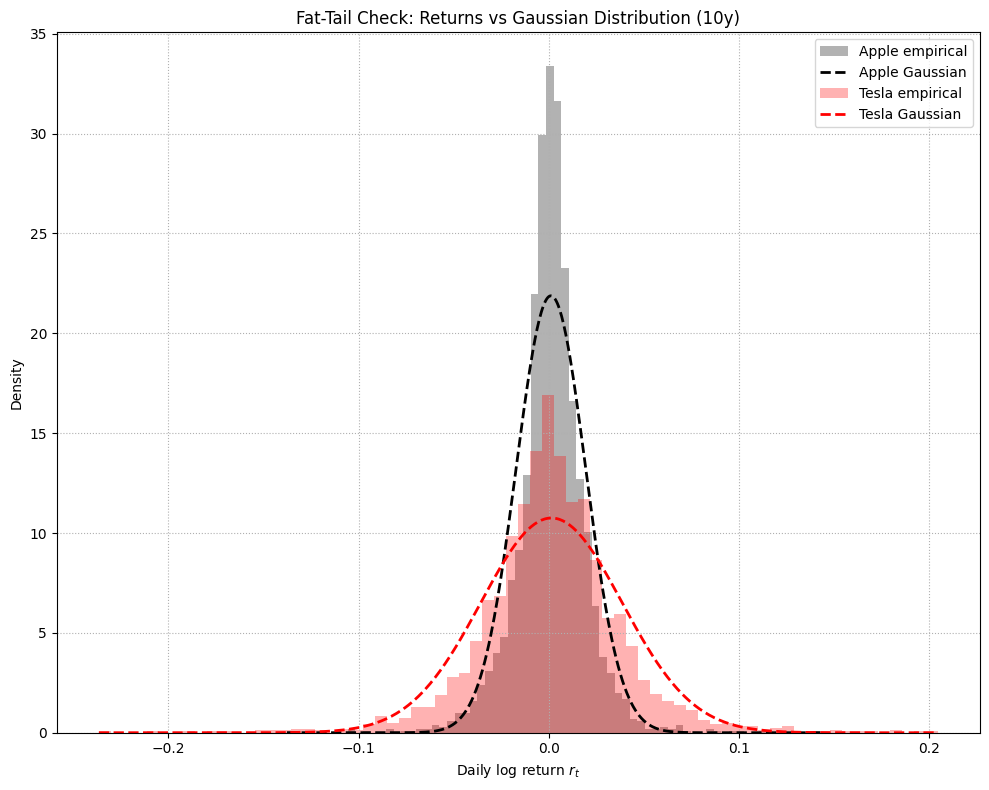

In [10]:
# Fat-tail check: histogram vs normal distribution + tests

import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, kurtosis, jarque_bera, kstest

tickers = {
    "Apple": ("AAPL", "black"),
    "Tesla": ("TSLA", "red"),
}

period = "10y"

plt.figure(figsize=(10, 8))

for name, (ticker, color) in tickers.items():

    df = yf.download(ticker, period=period, auto_adjust=True, progress=False)
    p = df["Close"].squeeze().dropna()

    r = np.log(p / p.shift(1)).dropna()

    mu = r.mean()
    sigma = r.std()

    x = np.linspace(r.min(), r.max(), 500)

    ex_kurt = kurtosis(r, fisher=True)
    jb_stat, jb_p = jarque_bera(r)

    z = (r - mu) / sigma
    ks_stat, ks_p = kstest(z, "norm")

    print(f"\n{name}")
    print(f"Excess kurtosis: {ex_kurt:.3f}")
    print(f"Jarque-Bera p-value: {jb_p:.5g}")
    print(f"KS p-value: {ks_p:.5g}")

    plt.hist(
        r,
        bins=70,
        density=True,
        alpha=0.30,
        color=color,
        label=f"{name} empirical"
    )

    plt.plot(
        x,
        norm.pdf(x, mu, sigma),
        color=color,
        linestyle="--",
        linewidth=2,
        label=f"{name} Gaussian"
    )

plt.xlabel(r"Daily log return $r_t$")
plt.ylabel("Density")
plt.title(f"Fat-Tail Check: Returns vs Gaussian Distribution ({period})")
plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

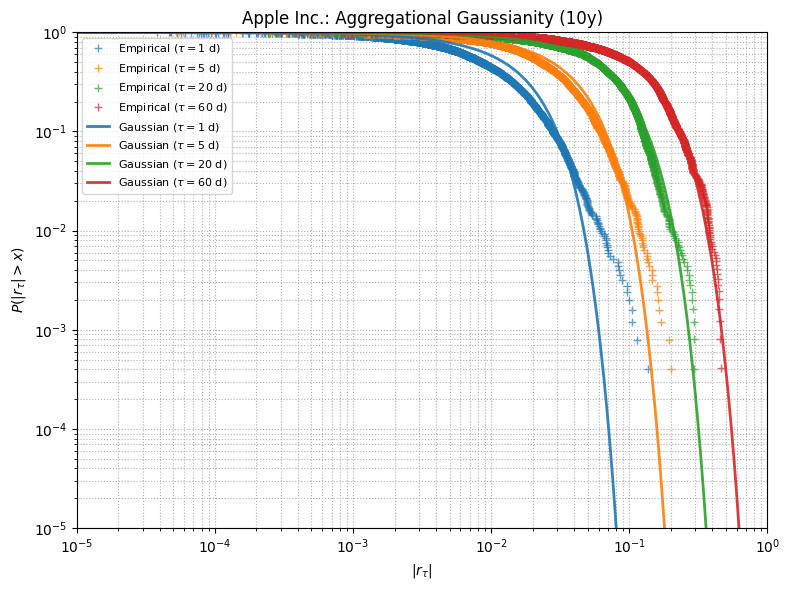

Aggregational Gaussianity Diagnostics
-------------------------------------------------------
tau= 1 days | KS distance=0.0814 | KS p-value=6.216e-15 | excess kurtosis=6.715
tau= 5 days | KS distance=0.0445 | KS p-value=9.403e-05 | excess kurtosis=2.539
tau=20 days | KS distance=0.0497 | KS p-value=8.564e-06 | excess kurtosis=0.625
tau=60 days | KS distance=0.0416 | KS p-value=0.0004028 | excess kurtosis=0.706


In [11]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

from scipy.stats import norm, kstest, kurtosis

# ============================================================
# 1. Data
# ============================================================
ticker = "AAPL"
asset_name = "Apple Inc."
period = "10y"

df = yf.download(ticker, period=period, auto_adjust=True, progress=False)

prices = df["Close"].squeeze().dropna()
returns = np.log(prices).diff().dropna()

# ============================================================
# 2. Helper functions
# ============================================================
def aggregate_returns(r, tau):
    return r.rolling(window=tau).sum().dropna()

def ccdf(data):
    x = np.sort(np.abs(data))
    y = 1.0 - np.arange(1, len(x) + 1) / len(x)

    # remove zero y-values for log-log plotting
    mask = y > 0
    return x[mask], y[mask]

# ============================================================
# 3. Parameters
# ============================================================
taus = [1, 5, 20, 60]
colors = ["tab:blue", "tab:orange", "tab:green", "tab:red"]

sigma1 = returns.std()
xg = np.logspace(-5, 0, 500)

# ============================================================
# 4. Plot: Aggregational Gaussianity
# ============================================================
plt.figure(figsize=(8, 6))

for tau, c in zip(taus, colors):
    r_tau = aggregate_returns(returns, tau)
    x, y = ccdf(r_tau)

    plt.loglog(
        x,
        y,
        marker="+",
        linestyle="None",
        color=c,
        alpha=0.7,
        label=fr"Empirical ($\tau={tau}$ d)"
    )

for tau, c in zip(taus, colors):
    sigma_tau = np.sqrt(tau) * sigma1
    yg = 2 * (1 - norm.cdf(xg / sigma_tau))

    plt.loglog(
        xg,
        yg,
        color=c,
        linewidth=2,
        alpha=0.9,
        label=fr"Gaussian ($\tau={tau}$ d)"
    )

plt.xlim(1e-5, 1)
plt.ylim(1e-5, 1)

plt.xlabel(r"$|r_\tau|$")
plt.ylabel(r"$P(|r_\tau| > x)$")
plt.title(f"{asset_name}: Aggregational Gaussianity ({period})")

plt.legend(fontsize=8)
plt.grid(True, which="both", linestyle=":")
plt.tight_layout()
plt.show()

# ============================================================
# 5. Quantitative tests
# ============================================================
print("Aggregational Gaussianity Diagnostics")
print("-" * 55)

for tau in taus:
    r_tau = aggregate_returns(returns, tau)
    z = (r_tau - r_tau.mean()) / r_tau.std()

    ks_stat, ks_p = kstest(z, "norm")
    ex_kurt = kurtosis(r_tau, fisher=True)

    print(
        f"tau={tau:>2} days | "
        f"KS distance={ks_stat:.4f} | "
        f"KS p-value={ks_p:.4g} | "
        f"excess kurtosis={ex_kurt:.3f}"
    )

Ljung-Box test for returns


,lb_stat,lb_pvalue
20,33.07612,0.03310



Ljung-Box test for absolute returns


,lb_stat,lb_pvalue
20,556.35303,0.00000



Selected autocorrelations
Return ACF lag 1  : -0.0157
Return ACF lag 5  : -0.0230
Return ACF lag 20 : 0.0084
|Return| ACF lag 1  : 0.1234
|Return| ACF lag 5  : 0.0994
|Return| ACF lag 20 : 0.0376


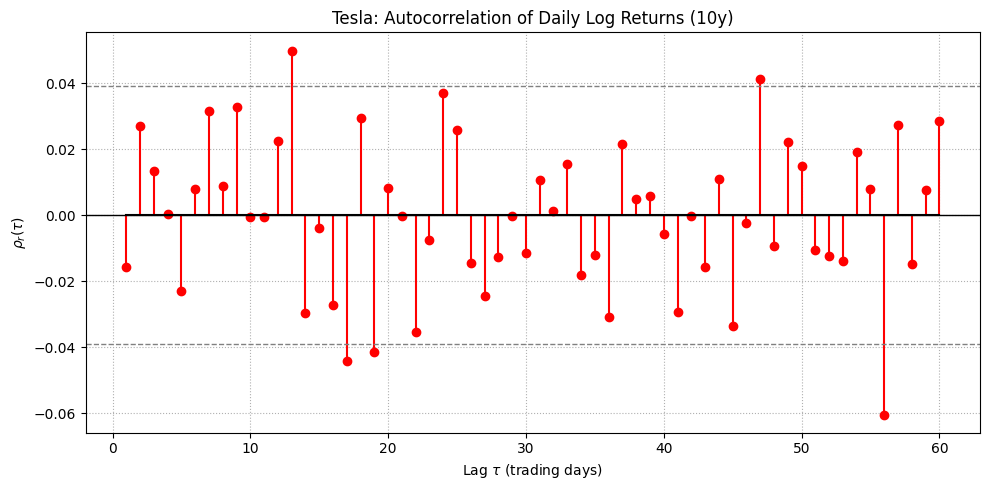

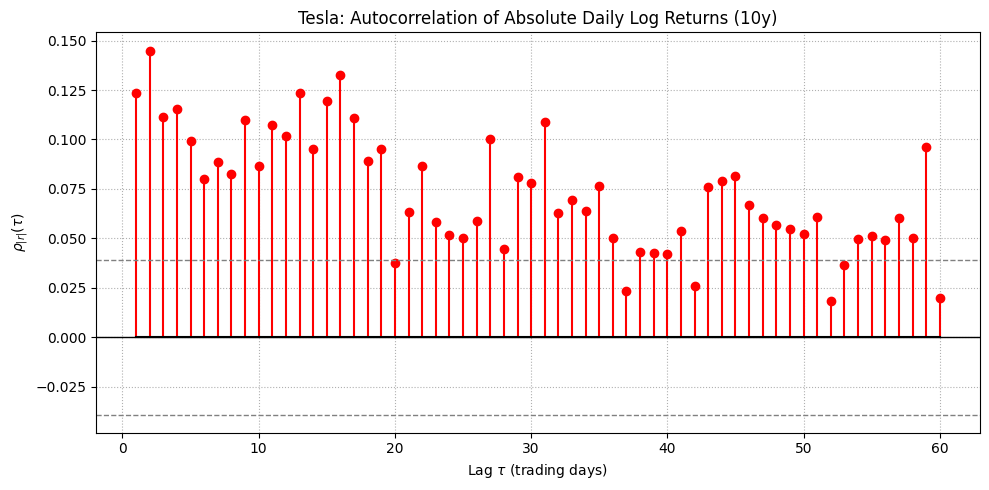

In [12]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox

# -----------------------------
# Parameters
# -----------------------------
ticker = "TSLA"
asset_name = "Tesla"
period = "10y"
max_lag = 60

# -----------------------------
# Download data
# -----------------------------
data = yf.download(
    ticker,
    period=period,
    interval="1d",
    auto_adjust=True,
    progress=False
)

prices = data["Close"].squeeze().dropna()

# -----------------------------
# Log returns
# -----------------------------
returns = np.log(prices / prices.shift(1)).dropna()
abs_returns = np.abs(returns)

# -----------------------------
# Autocorrelation functions
# -----------------------------
lags = np.arange(1, max_lag + 1)

acf_returns = np.array([
    returns.autocorr(lag=lag)
    for lag in lags
])

acf_abs_returns = np.array([
    abs_returns.autocorr(lag=lag)
    for lag in lags
])

# 95% confidence band
conf = 1.96 / np.sqrt(len(returns))

# -----------------------------
# Ljung-Box tests
# -----------------------------
lb_returns = acorr_ljungbox(returns, lags=[20], return_df=True)
lb_abs_returns = acorr_ljungbox(abs_returns, lags=[20], return_df=True)

print("Ljung-Box test for returns")
display(lb_returns)

print("\nLjung-Box test for absolute returns")
display(lb_abs_returns)

print("\nSelected autocorrelations")
print(f"Return ACF lag 1  : {returns.autocorr(1):.4f}")
print(f"Return ACF lag 5  : {returns.autocorr(5):.4f}")
print(f"Return ACF lag 20 : {returns.autocorr(20):.4f}")
print(f"|Return| ACF lag 1  : {abs_returns.autocorr(1):.4f}")
print(f"|Return| ACF lag 5  : {abs_returns.autocorr(5):.4f}")
print(f"|Return| ACF lag 20 : {abs_returns.autocorr(20):.4f}")

# -----------------------------
# Plot 1: ACF of returns
# -----------------------------
plt.figure(figsize=(10, 5))

plt.stem(
    lags,
    acf_returns,
    linefmt="r-",
    markerfmt="ro",
    basefmt="k-"
)

plt.axhline(0, color="black", linewidth=1)
plt.axhline(conf, color="gray", linestyle="--", linewidth=1)
plt.axhline(-conf, color="gray", linestyle="--", linewidth=1)

plt.xlabel(r"Lag $\tau$ (trading days)")
plt.ylabel(r"$\rho_r(\tau)$")
plt.title(f"{asset_name}: Autocorrelation of Daily Log Returns ({period})")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

# -----------------------------
# Plot 2: ACF of absolute returns
# -----------------------------
plt.figure(figsize=(10, 5))

plt.stem(
    lags,
    acf_abs_returns,
    linefmt="r-",
    markerfmt="ro",
    basefmt="k-"
)

plt.axhline(0, color="black", linewidth=1)
plt.axhline(conf, color="gray", linestyle="--", linewidth=1)
plt.axhline(-conf, color="gray", linestyle="--", linewidth=1)

plt.xlabel(r"Lag $\tau$ (trading days)")
plt.ylabel(r"$\rho_{|r|}(\tau)$")
plt.title(f"{asset_name}: Autocorrelation of Absolute Daily Log Returns ({period})")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

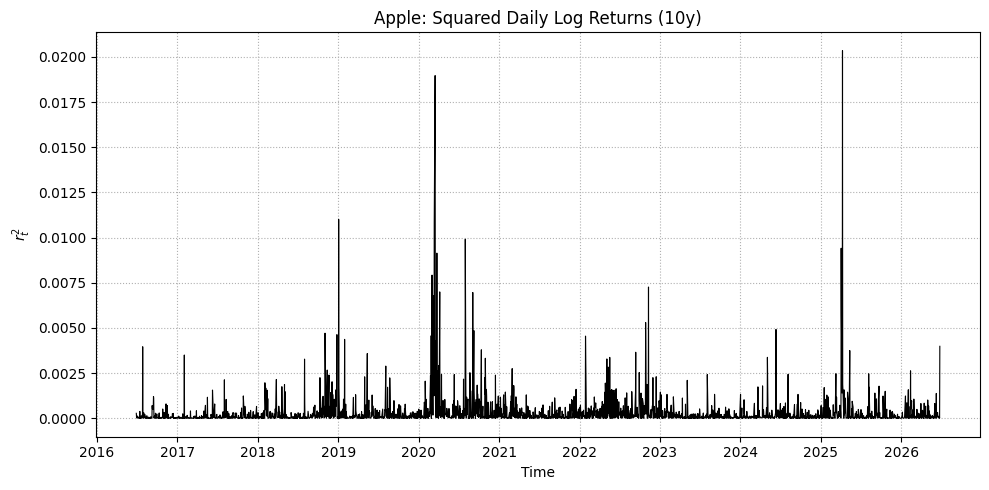

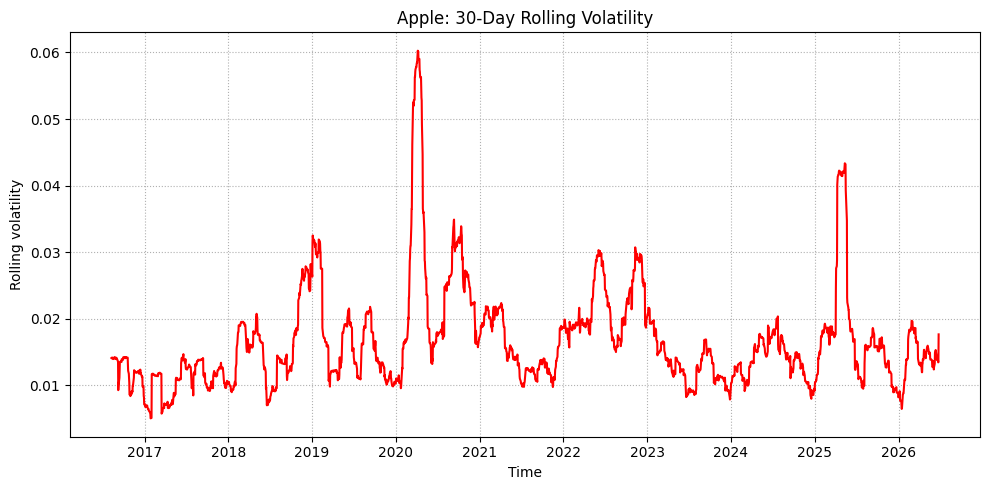

In [13]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Parameters
# -----------------------------
ticker = "AAPL"
asset_name = "Apple"
period = "10y"
rolling_window = 30

# -----------------------------
# Download data
# -----------------------------
data = yf.download(
    ticker,
    period=period,
    interval="1d",
    auto_adjust=True,
    progress=False
)

prices = data["Close"].squeeze().dropna()

# -----------------------------
# Daily log returns
# -----------------------------
returns = np.log(prices / prices.shift(1)).dropna()

# -----------------------------
# Squared returns
# -----------------------------
squared_returns = returns**2

# 30-day rolling volatility
rolling_vol = returns.rolling(rolling_window).std()

# -----------------------------
# Plot 1: Squared returns
# -----------------------------
plt.figure(figsize=(10,5))

plt.plot(
    squared_returns.index,
    squared_returns,
    color="black",
    linewidth=0.8
)

plt.xlabel("Time")
plt.ylabel(r"$r_t^2$")
plt.title(f"{asset_name}: Squared Daily Log Returns ({period})")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

# -----------------------------
# Plot 2: Rolling volatility
# -----------------------------
plt.figure(figsize=(10,5))

plt.plot(
    rolling_vol.index,
    rolling_vol,
    color="red",
    linewidth=1.5
)

plt.xlabel("Time")
plt.ylabel("Rolling volatility")
plt.title(f"{asset_name}: {rolling_window}-Day Rolling Volatility")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

This one is already good. I'd just make it more publication-ready and add a rolling volatility overlay, which makes volatility clustering much clearer.

In [14]:
from statsmodels.stats.diagnostic import het_arch

arch_stat, arch_p, _, _ = het_arch(returns, nlags=20)

print(f"ARCH-LM statistic : {arch_stat:.3f}")
print(f"ARCH-LM p-value   : {arch_p:.5g}")

ARCH-LM statistic : 366.596
ARCH-LM p-value   : 1.6787e-65


I'd also add one quantitative test
Since this plot is meant to demonstrate volatility clustering, accompany it with the ARCH-LM test:

Interpretation

Squared returns plot: Shows bursts of high and low volatility. Clusters of large r_2 ^ 2 values indicate that large price movements tend to be followed by large price movements.

Rolling volatility: Smoothly highlights periods of elevated and subdued market risk, making the clustering easier to see.

ARCH-LM test: A small p-value (typically < 0.05) provides statistical evidence for conditional heteroskedasticity, supporting the visual observation of volatility clustering.

Ljung-Box test at lag 20
----------------------------------------
Returns:


,lb_stat,lb_pvalue
20,54.64684,0.00005


Absolute returns:


,lb_stat,lb_pvalue
20,2957.87501,0.00000


Squared returns:


,lb_stat,lb_pvalue
20,1920.86798,0.00000


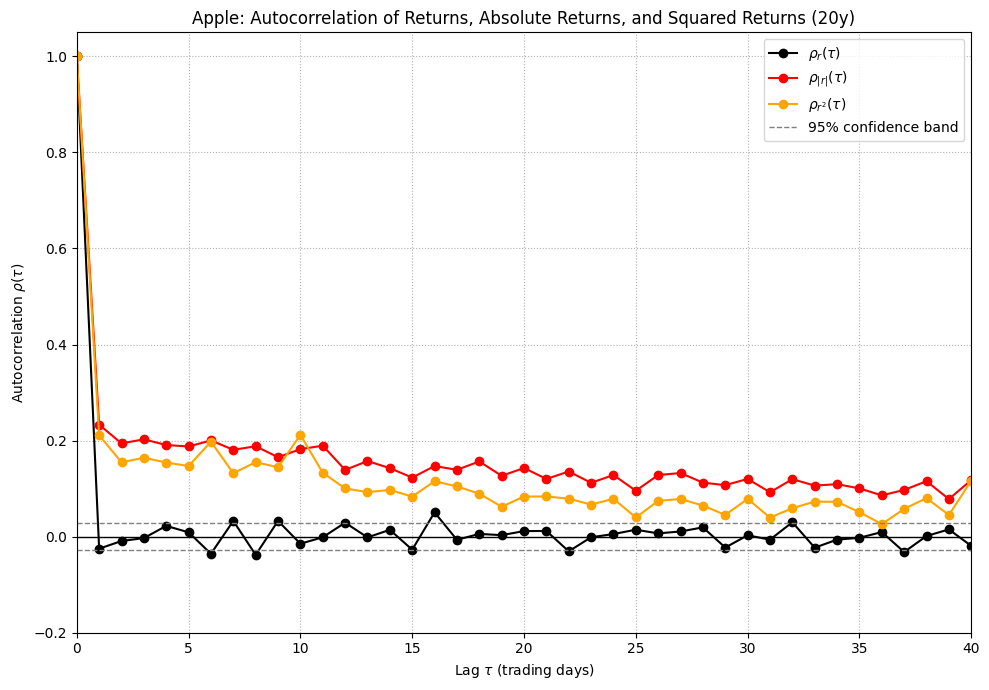

In [15]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import acorr_ljungbox

# -----------------------------
# Parameters
# -----------------------------
ticker = "AAPL"
asset_name = "Apple"
period = "20y"
max_lag = 40

# -----------------------------
# Download data
# -----------------------------
data = yf.download(
    ticker,
    period=period,
    interval="1d",
    auto_adjust=True,
    progress=False
)

prices = data["Close"].squeeze().dropna()

# -----------------------------
# Log returns
# -----------------------------
returns = np.log(prices / prices.shift(1)).dropna()
abs_returns = np.abs(returns)
sq_returns = returns**2

# -----------------------------
# Autocorrelations
# -----------------------------
lags = np.arange(0, max_lag + 1)

acf_r = np.array([returns.autocorr(lag=l) if l > 0 else 1 for l in lags])
acf_abs = np.array([abs_returns.autocorr(lag=l) if l > 0 else 1 for l in lags])
acf_sq = np.array([sq_returns.autocorr(lag=l) if l > 0 else 1 for l in lags])

conf = 1.96 / np.sqrt(len(returns))

# -----------------------------
# Ljung-Box tests
# -----------------------------
print("Ljung-Box test at lag 20")
print("-" * 40)
print("Returns:")
display(acorr_ljungbox(returns, lags=[20], return_df=True))

print("Absolute returns:")
display(acorr_ljungbox(abs_returns, lags=[20], return_df=True))

print("Squared returns:")
display(acorr_ljungbox(sq_returns, lags=[20], return_df=True))

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(10, 7))

plt.plot(lags, acf_r, marker="o", label=r"$\rho_r(\tau)$", color="black")
plt.plot(lags, acf_abs, marker="o", label=r"$\rho_{|r|}(\tau)$", color="red")
plt.plot(lags, acf_sq, marker="o", label=r"$\rho_{r^2}(\tau)$", color="orange")

plt.axhline(0, color="black", linewidth=1)
plt.axhline(conf, color="gray", linestyle="--", linewidth=1, label="95% confidence band")
plt.axhline(-conf, color="gray", linestyle="--", linewidth=1)

plt.xlabel(r"Lag $\tau$ (trading days)")
plt.ylabel(r"Autocorrelation $\rho(\tau)$")
plt.title(f"{asset_name}: Autocorrelation of Returns, Absolute Returns, and Squared Returns ({period})")

plt.xlim(0, max_lag)
plt.ylim(-0.2, 1.05)

plt.legend()
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

Expected interpretation: raw returns should decay near zero quickly, while absolute and squared returns remain positive for longer. This supports volatility clustering.

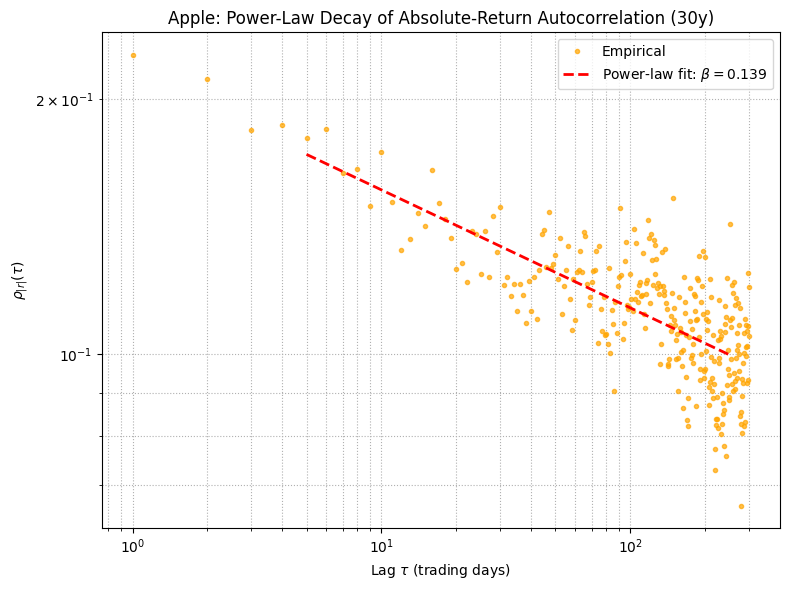

beta = 0.1394
R²    = 0.4998
Fit range: 5 to 250 lags


In [16]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# -----------------------------
# Parameters
# -----------------------------
ticker = "AAPL"
asset_name = "Apple"
period = "30y"
max_lag = 1000

fit_min_lag = 5
fit_max_lag = 250
plot_max_lag = 300

# -----------------------------
# Download data
# -----------------------------
data = yf.download(
    ticker,
    period=period,
    interval="1d",
    auto_adjust=True,
    progress=False
)

prices = data["Close"].squeeze().dropna()

# -----------------------------
# Log returns and absolute returns
# -----------------------------
returns = np.log(prices / prices.shift(1)).dropna()
abs_returns = np.abs(returns)

# -----------------------------
# Autocorrelation of absolute returns
# -----------------------------
lags = np.arange(1, max_lag + 1)

acf_abs = np.array([
    abs_returns.autocorr(lag=lag)
    for lag in lags
])

# -----------------------------
# Power-law fit only on meaningful region
# rho(tau) ~ tau^(-beta)
# -----------------------------
fit_mask = (
    (lags >= fit_min_lag) &
    (lags <= fit_max_lag) &
    (acf_abs > 0)
)

lags_fit = lags[fit_mask]
acf_fit = acf_abs[fit_mask]

slope, intercept, r_value, p_value, std_err = linregress(
    np.log(lags_fit),
    np.log(acf_fit)
)

beta = -slope
acf_powerlaw = np.exp(intercept) * lags_fit ** (-beta)

# -----------------------------
# Plot: log-log version
# -----------------------------
plt.figure(figsize=(8, 6))

plot_mask = (
    (lags <= plot_max_lag) &
    (acf_abs > 0)
)

plt.loglog(
    lags[plot_mask],
    acf_abs[plot_mask],
    "o",
    ms=3,
    alpha=0.7,
    color="orange",
    label="Empirical"
)

plt.loglog(
    lags_fit,
    acf_powerlaw,
    "--",
    lw=2,
    color="red",
    label=fr"Power-law fit: $\beta={beta:.3f}$"
)

plt.xlabel(r"Lag $\tau$ (trading days)")
plt.ylabel(r"$\rho_{|r|}(\tau)$")
plt.title(f"{asset_name}: Power-Law Decay of Absolute-Return Autocorrelation ({period})")
plt.legend()
plt.grid(True, which="both", linestyle=":")
plt.tight_layout()
plt.show()

print(f"beta = {beta:.4f}")
print(f"R²    = {r_value**2:.4f}")
print(f"Fit range: {fit_min_lag} to {fit_max_lag} lags")

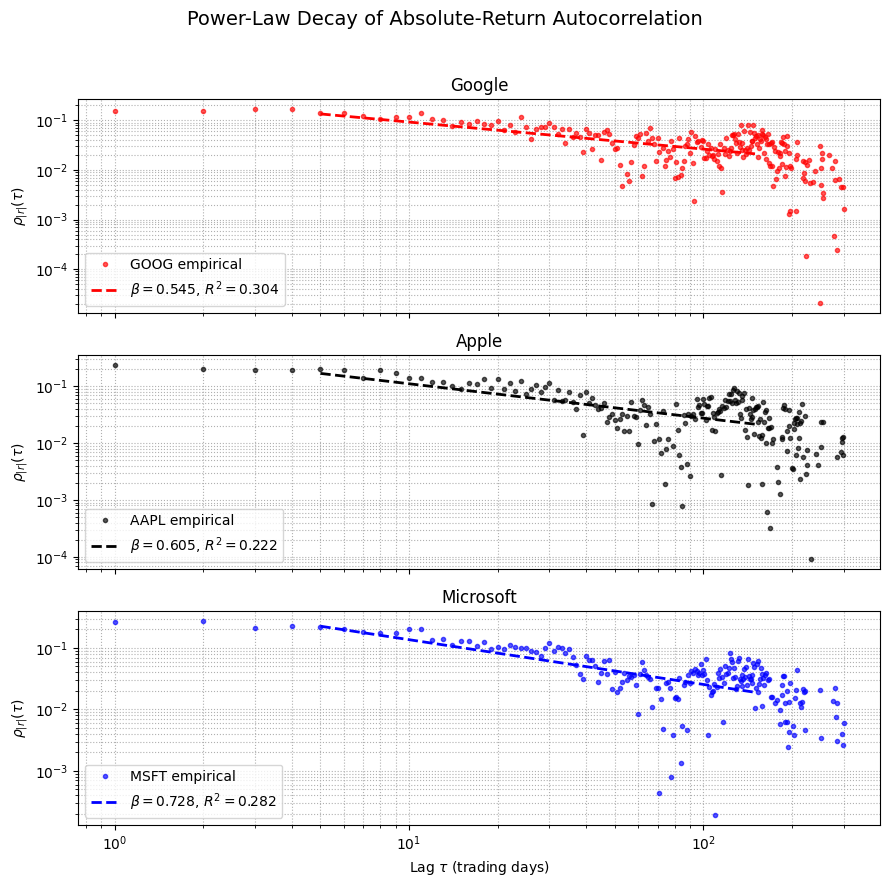

In [17]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# -----------------------------
# Parameters
# -----------------------------
tickers = {
    "Google": ("GOOG", "red"),
    "Apple": ("AAPL", "black"),
    "Microsoft": ("MSFT", "blue"),
}

period = "10y"
max_lag = 500
fit_min_lag = 5
fit_max_lag = 150
plot_max_lag = 300

# -----------------------------
# Create figure
# -----------------------------
fig, axes = plt.subplots(len(tickers), 1, figsize=(9, 9), sharex=True)

for ax, (name, (ticker, color)) in zip(axes, tickers.items()):

    data = yf.download(
        ticker,
        period=period,
        interval="1d",
        auto_adjust=True,
        progress=False
    )

    prices = data["Close"].squeeze().dropna()
    returns = np.log(prices / prices.shift(1)).dropna()
    abs_returns = np.abs(returns)

    lags = np.arange(1, max_lag + 1)

    acf_abs = np.array([
        abs_returns.autocorr(lag=lag)
        for lag in lags
    ])

    fit_mask = (
        (lags >= fit_min_lag) &
        (lags <= fit_max_lag) &
        (acf_abs > 0)
    )

    lags_fit = lags[fit_mask]
    acf_fit = acf_abs[fit_mask]

    slope, intercept, r_value, p_value, std_err = linregress(
        np.log(lags_fit),
        np.log(acf_fit)
    )

    beta = -slope
    acf_powerlaw = np.exp(intercept) * lags_fit ** (-beta)

    plot_mask = (lags <= plot_max_lag) & (acf_abs > 0)

    ax.loglog(
        lags[plot_mask],
        acf_abs[plot_mask],
        "o",
        ms=3,
        alpha=0.65,
        color=color,
        label=f"{ticker} empirical"
    )

    ax.loglog(
        lags_fit,
        acf_powerlaw,
        "--",
        linewidth=2,
        color=color,
        label=fr"$\beta={beta:.3f}$, $R^2={r_value**2:.3f}$"
    )

    ax.set_ylabel(r"$\rho_{|r|}(\tau)$")
    ax.set_title(name)
    ax.legend()
    ax.grid(True, which="both", linestyle=":")

axes[-1].set_xlabel(r"Lag $\tau$ (trading days)")

plt.suptitle("Power-Law Decay of Absolute-Return Autocorrelation", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

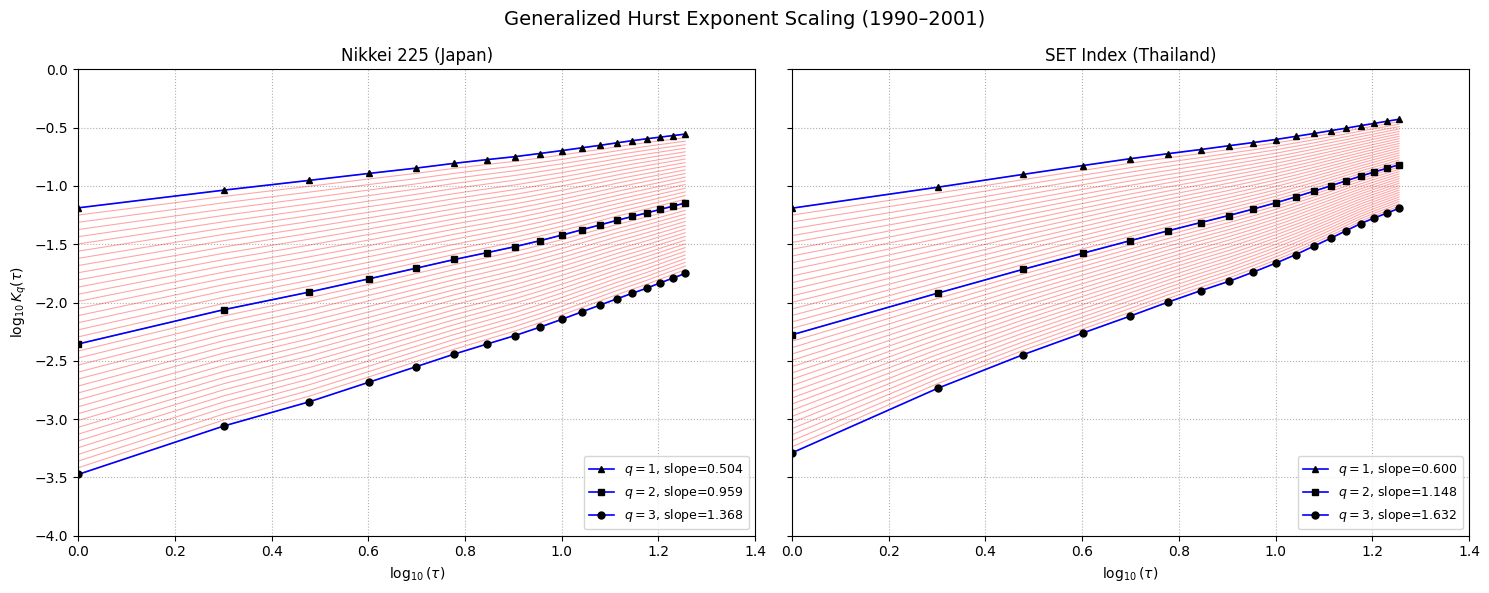

In [18]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# --------------------------------
# Parameters
# --------------------------------
taus = np.arange(1, 19)
start = "1990-01-01"
end = "2001-12-31"

q_low = np.linspace(1.0, 2.0, 20)
q_high = np.linspace(2.0, 3.0, 20)
qs = np.concatenate([q_low, q_high])

q_highlight = [1, 2, 3]

markets = {
    "Nikkei 225 (Japan)": "^N225",
    "SET Index (Thailand)": "^SET.BK"
}

marker_map = {
    1: "^",
    2: "s",
    3: "o"
}

X_LIM = (0, 1.4)
Y_LIM = (-4, 0)

# --------------------------------
# GHE estimator
# --------------------------------
def generalized_hurst_Kq(log_prices, q, taus):
    X = np.asarray(log_prices).flatten()

    denom = np.mean(np.abs(X) ** q)

    Kq = []
    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)

# --------------------------------
# Plot
# --------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)

for ax, (title, ticker) in zip(axes, markets.items()):

    prices = yf.download(
        ticker,
        start=start,
        end=end,
        auto_adjust=True,
        progress=False
    )["Close"].squeeze().dropna()

    log_prices = np.log(prices)
    log_prices = log_prices - log_prices.mean()

    x = np.log10(taus)

    # all q curves
    for q in qs:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        y = np.log10(Kq)

        ax.plot(
            x,
            y,
            color="red",
            alpha=0.35,
            linewidth=0.8
        )

    # highlighted q curves
    for q in q_highlight:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        y = np.log10(Kq)

        slope, intercept, r_value, p_value, std_err = linregress(x, y)

        ax.plot(
            x,
            y,
            marker=marker_map[q],
            linestyle="-",
            linewidth=1.2,
            markersize=5,
            color="blue",
            markerfacecolor="black",
            markeredgecolor="black",
            label=fr"$q={q}$, slope={slope:.3f}"
        )

    ax.set_title(title)
    ax.set_xlim(X_LIM)
    ax.set_ylim(Y_LIM)
    ax.set_xlabel(r"$\log_{10}(\tau)$")
    ax.grid(True, linestyle=":")
    ax.legend(loc="lower right", frameon=True, fontsize=9)

axes[0].set_ylabel(r"$\log_{10} K_q(\tau)$")

plt.suptitle("Generalized Hurst Exponent Scaling (1990–2001)", fontsize=14)
plt.tight_layout()
plt.show()

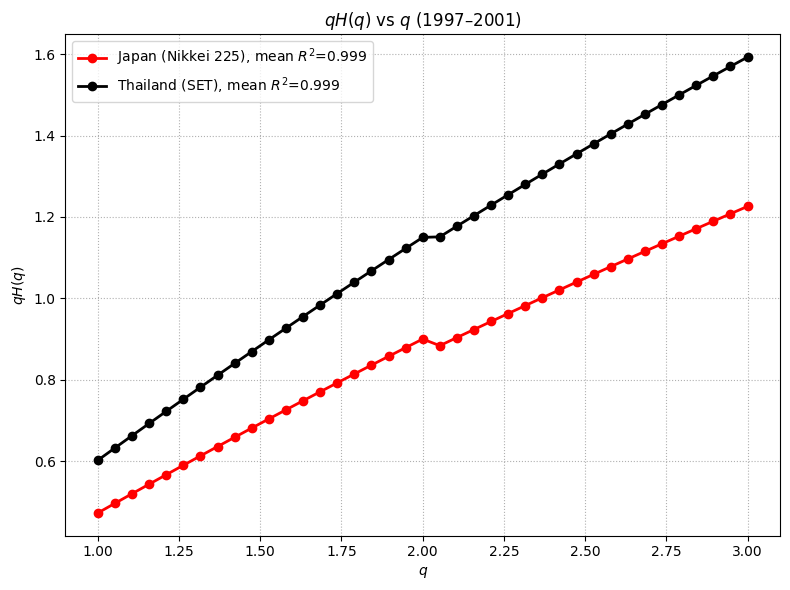

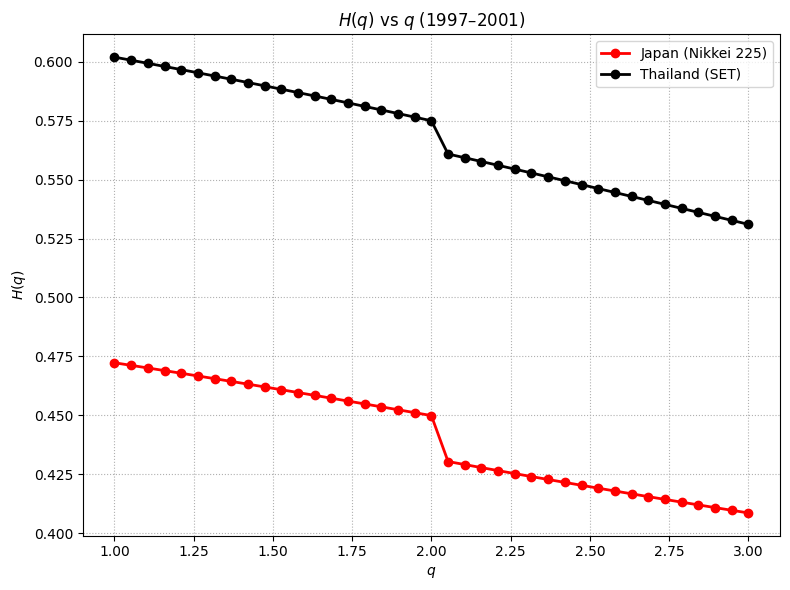

In [19]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# --------------------------------
# Parameters
# --------------------------------
start = "1997-01-01"
end = "2001-12-31"

q_low = np.linspace(1.0, 2.0, 20, endpoint=True)
q_high = np.linspace(2.0, 3.0, 20, endpoint=True)[1:]
qs = np.concatenate([q_low, q_high])

tau_low = np.arange(1, 19)
tau_high = np.arange(1, 12)

markets = {
    "Japan (Nikkei 225)": ("^N225", "red"),
    "Thailand (SET)": ("^SET.BK", "black")
}

# --------------------------------
# GHE estimator
# --------------------------------
def generalized_hurst_Kq(log_prices, q, taus):
    X = np.asarray(log_prices).flatten()

    denom = np.mean(np.abs(X) ** q)

    Kq = []
    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)

# --------------------------------
# Estimate qH(q)
# --------------------------------
results = {}

for label, (ticker, color) in markets.items():

    prices = yf.download(
        ticker,
        start=start,
        end=end,
        auto_adjust=True,
        progress=False
    )["Close"].squeeze().dropna()

    log_prices = np.log(prices)
    log_prices = log_prices - log_prices.mean()

    qHq = []
    Hq = []
    r2s = []

    for q in qs:
        taus = tau_low if q <= 2 else tau_high

        Kq = generalized_hurst_Kq(log_prices, q, taus)

        x = np.log10(taus)
        y = np.log10(Kq)

        slope, intercept, r_value, p_value, std_err = linregress(x, y)

        qHq.append(slope)
        Hq.append(slope / q)
        r2s.append(r_value**2)

    results[label] = {
        "color": color,
        "qHq": np.array(qHq),
        "Hq": np.array(Hq),
        "r2": np.array(r2s)
    }

# --------------------------------
# Plot 1: qH(q)
# --------------------------------
plt.figure(figsize=(8, 6))

for label, res in results.items():
    plt.plot(
        qs,
        res["qHq"],
        marker="o",
        linewidth=2,
        color=res["color"],
        label=fr"{label}, mean $R^2$={res['r2'].mean():.3f}"
    )

plt.xlabel(r"$q$")
plt.ylabel(r"$qH(q)$")
plt.title(r"$qH(q)$ vs $q$ (1997–2001)")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------
# Plot 2: H(q)
# --------------------------------
plt.figure(figsize=(8, 6))

for label, res in results.items():
    plt.plot(
        qs,
        res["Hq"],
        marker="o",
        linewidth=2,
        color=res["color"],
        label=label
    )

plt.xlabel(r"$q$")
plt.ylabel(r"$H(q)$")
plt.title(r"$H(q)$ vs $q$ (1997–2001)")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

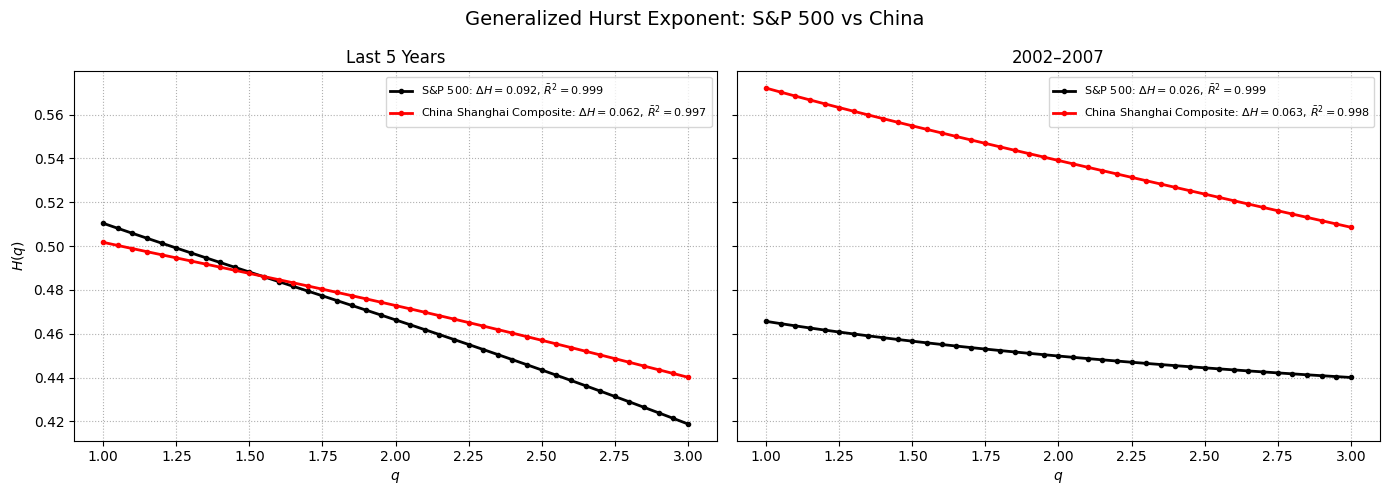

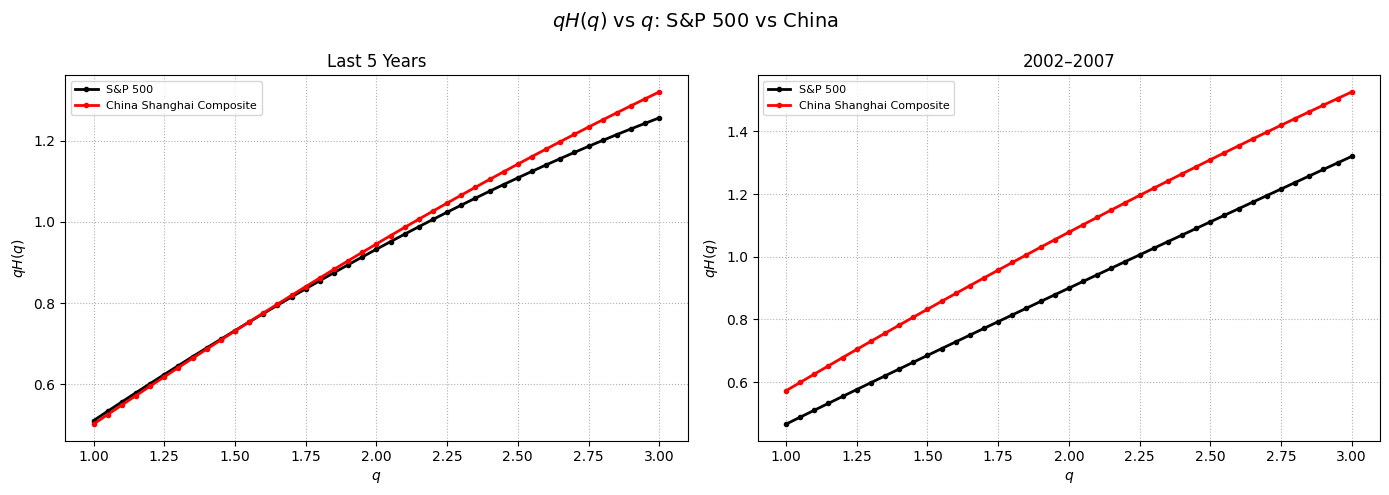

Summary
--------------------------------------------------------------------------------

Last 5 Years
S&P 500                   | N=1254 | H(1)=0.510 | H(3)=0.419 | Delta H=0.092 | Mean R2=0.999
China Shanghai Composite  | N=1210 | H(1)=0.502 | H(3)=0.440 | Delta H=0.062 | Mean R2=0.997

2002–2007
S&P 500                   | N=1509 | H(1)=0.466 | H(3)=0.440 | Delta H=0.026 | Mean R2=0.999
China Shanghai Composite  | N=1445 | H(1)=0.572 | H(3)=0.509 | Delta H=0.063 | Mean R2=0.998


In [20]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ============================================================
# Parameters
# ============================================================

periods = {
    "Last 5 Years": {
        "period": "5y",
        "start": None,
        "end": None,
    },
    "2002–2007": {
        "period": None,
        "start": "2002-01-01",
        "end": "2007-12-31",
    }
}

markets = {
    "S&P 500": ("^GSPC", "black"),
    "China Shanghai Composite": ("000001.SS", "red"),
}

qs = np.linspace(1.0, 3.0, 41)
taus = np.arange(1, 20)

# ============================================================
# GHE estimator
# ============================================================

def generalized_hurst_Kq(log_prices, q, taus):
    X = np.asarray(log_prices).flatten()

    denom = np.mean(np.abs(X) ** q)

    Kq = []
    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)


def estimate_Hq(prices, qs, taus):
    log_prices = np.log(prices)
    log_prices = log_prices - log_prices.mean()

    qHq = []
    Hq = []
    r2s = []

    x = np.log10(taus)

    for q in qs:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        y = np.log10(Kq)

        slope, intercept, r_value, p_value, std_err = linregress(x, y)

        qHq.append(slope)
        Hq.append(slope / q)
        r2s.append(r_value**2)

    return np.array(qHq), np.array(Hq), np.array(r2s)


# ============================================================
# Run estimation
# ============================================================

all_results = {}

for period_label, period_info in periods.items():

    all_results[period_label] = {}

    for market_name, (ticker, color) in markets.items():

        if period_info["period"] is not None:
            df = yf.download(
                ticker,
                period=period_info["period"],
                auto_adjust=True,
                progress=False
            )
        else:
            df = yf.download(
                ticker,
                start=period_info["start"],
                end=period_info["end"],
                auto_adjust=True,
                progress=False
            )

        prices = df["Close"].squeeze().dropna()

        qHq, Hq, r2s = estimate_Hq(prices, qs, taus)

        all_results[period_label][market_name] = {
            "ticker": ticker,
            "color": color,
            "prices": prices,
            "qHq": qHq,
            "Hq": Hq,
            "r2s": r2s,
            "delta_H": Hq[0] - Hq[-1],
            "mean_R2": r2s.mean(),
            "N": len(prices)
        }


# ============================================================
# Plot 1: H(q) vs q
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (period_label, result_dict) in zip(axes, all_results.items()):

    for market_name, res in result_dict.items():

        ax.plot(
            qs,
            res["Hq"],
            marker="o",
            markersize=3,
            linewidth=2,
            color=res["color"],
            label=(
                fr"{market_name}: "
                fr"$\Delta H={res['delta_H']:.3f}$, "
                fr"$\bar R^2={res['mean_R2']:.3f}$"
            )
        )

    ax.set_title(period_label)
    ax.set_xlabel(r"$q$")
    ax.grid(True, linestyle=":")
    ax.legend(fontsize=8)

axes[0].set_ylabel(r"$H(q)$")

plt.suptitle("Generalized Hurst Exponent: S&P 500 vs China", fontsize=14)
plt.tight_layout()
plt.show()


# ============================================================
# Plot 2: qH(q) vs q
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, (period_label, result_dict) in zip(axes, all_results.items()):

    for market_name, res in result_dict.items():

        ax.plot(
            qs,
            res["qHq"],
            marker="o",
            markersize=3,
            linewidth=2,
            color=res["color"],
            label=market_name
        )

    ax.set_title(period_label)
    ax.set_xlabel(r"$q$")
    ax.set_ylabel(r"$qH(q)$")
    ax.grid(True, linestyle=":")
    ax.legend(fontsize=8)

plt.suptitle(r"$qH(q)$ vs $q$: S&P 500 vs China", fontsize=14)
plt.tight_layout()
plt.show()


# ============================================================
# Summary table
# ============================================================

print("Summary")
print("-" * 80)

for period_label, result_dict in all_results.items():
    print(f"\n{period_label}")

    for market_name, res in result_dict.items():
        print(
            f"{market_name:25s} | "
            f"N={res['N']:4d} | "
            f"H(1)={res['Hq'][0]:.3f} | "
            f"H(3)={res['Hq'][-1]:.3f} | "
            f"Delta H={res['delta_H']:.3f} | "
            f"Mean R2={res['mean_R2']:.3f}"
        )

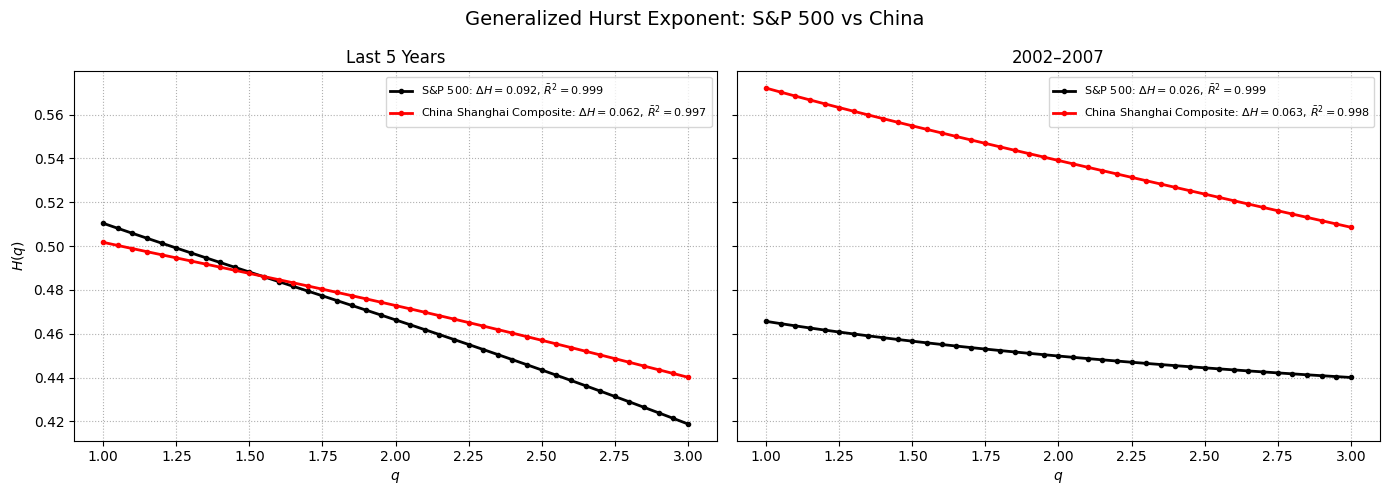

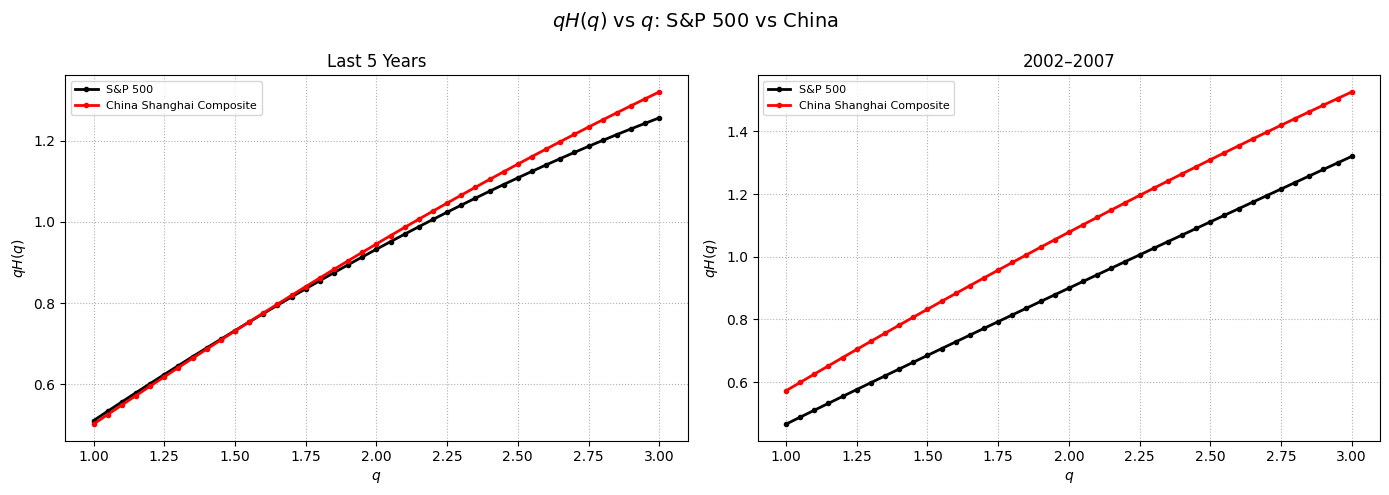

Summary
------------------------------------------------------------------------------------------

Last 5 Years
S&P 500                      | N=1254 | H(1)=0.510 | H(3)=0.419 | Delta H=0.092 | Mean R2=0.999
China Shanghai Composite     | N=1210 | H(1)=0.502 | H(3)=0.440 | Delta H=0.062 | Mean R2=0.997

2002–2007
S&P 500                      | N=1509 | H(1)=0.466 | H(3)=0.440 | Delta H=0.026 | Mean R2=0.999
China Shanghai Composite     | N=1445 | H(1)=0.572 | H(3)=0.509 | Delta H=0.063 | Mean R2=0.998


In [23]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# ============================================================
# Parameters
# ============================================================

periods = {
    "Last 5 Years": {
        "period": "5y",
        "start": None,
        "end": None,
    },
    "2002–2007": {
        "period": None,
        "start": "2002-01-01",
        "end": "2007-12-31",
    }
}

markets = {
    "S&P 500": ("^GSPC", "black"),
    "China Shanghai Composite": ("000001.SS", "red"),
}

#markets = {
#    "S&P 500 (USA)": ("^GSPC", "black"),
#    "Bovespa (Brazil)": ("^BVSP", "red")
#}


qs = np.linspace(1.0, 3.0, 41)
taus = np.arange(1, 20)

# ============================================================
# Structure function estimator
# S_q(tau) = E(|X(t+tau) - X(t)|^q)
# S_q(tau) ~ tau^{qH(q)}
# ============================================================

def structure_function(log_prices, q, taus):
    X = np.asarray(log_prices).flatten()

    Sq = []

    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Sq.append(np.mean(np.abs(diff) ** q))

    return np.array(Sq)


def estimate_Hq(prices, qs, taus):
    log_prices = np.log(prices)

    qHq = []
    Hq = []
    r2s = []

    x = np.log10(taus)

    for q in qs:
        Sq = structure_function(log_prices, q, taus)
        y = np.log10(Sq)

        slope, intercept, r_value, p_value, std_err = linregress(x, y)

        qHq.append(slope)
        Hq.append(slope / q)
        r2s.append(r_value**2)

    return np.array(qHq), np.array(Hq), np.array(r2s)


# ============================================================
# Run estimation
# ============================================================

all_results = {}

for period_label, period_info in periods.items():

    all_results[period_label] = {}

    for market_name, (ticker, color) in markets.items():

        if period_info["period"] is not None:
            df = yf.download(
                ticker,
                period=period_info["period"],
                auto_adjust=True,
                progress=False
            )
        else:
            df = yf.download(
                ticker,
                start=period_info["start"],
                end=period_info["end"],
                auto_adjust=True,
                progress=False
            )

        prices = df["Close"].squeeze().dropna()

        qHq, Hq, r2s = estimate_Hq(prices, qs, taus)

        all_results[period_label][market_name] = {
            "ticker": ticker,
            "color": color,
            "prices": prices,
            "qHq": qHq,
            "Hq": Hq,
            "r2s": r2s,
            "delta_H": Hq[0] - Hq[-1],
            "mean_R2": r2s.mean(),
            "N": len(prices)
        }


# ============================================================
# Plot 1: H(q) vs q
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, (period_label, result_dict) in zip(axes, all_results.items()):

    for market_name, res in result_dict.items():

        ax.plot(
            qs,
            res["Hq"],
            marker="o",
            markersize=3,
            linewidth=2,
            color=res["color"],
            label=(
                fr"{market_name}: "
                fr"$\Delta H={res['delta_H']:.3f}$, "
                fr"$\bar R^2={res['mean_R2']:.3f}$"
            )
        )

    ax.set_title(period_label)
    ax.set_xlabel(r"$q$")
    ax.grid(True, linestyle=":")
    ax.legend(fontsize=8)

axes[0].set_ylabel(r"$H(q)$")

plt.suptitle("Generalized Hurst Exponent: S&P 500 vs China", fontsize=14)
plt.tight_layout()
plt.show()


# ============================================================
# Plot 2: qH(q) vs q
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

for ax, (period_label, result_dict) in zip(axes, all_results.items()):

    for market_name, res in result_dict.items():

        ax.plot(
            qs,
            res["qHq"],
            marker="o",
            markersize=3,
            linewidth=2,
            color=res["color"],
            label=market_name
        )

    ax.set_title(period_label)
    ax.set_xlabel(r"$q$")
    ax.set_ylabel(r"$qH(q)$")
    ax.grid(True, linestyle=":")
    ax.legend(fontsize=8)

plt.suptitle(r"$qH(q)$ vs $q$: S&P 500 vs China", fontsize=14)
plt.tight_layout()
plt.show()


# ============================================================
# Summary table
# ============================================================

print("Summary")
print("-" * 90)

for period_label, result_dict in all_results.items():

    print(f"\n{period_label}")

    for market_name, res in result_dict.items():

        print(
            f"{market_name:28s} | "
            f"N={res['N']:4d} | "
            f"H(1)={res['Hq'][0]:.3f} | "
            f"H(3)={res['Hq'][-1]:.3f} | "
            f"Delta H={res['delta_H']:.3f} | "
            f"Mean R2={res['mean_R2']:.3f}"
        )

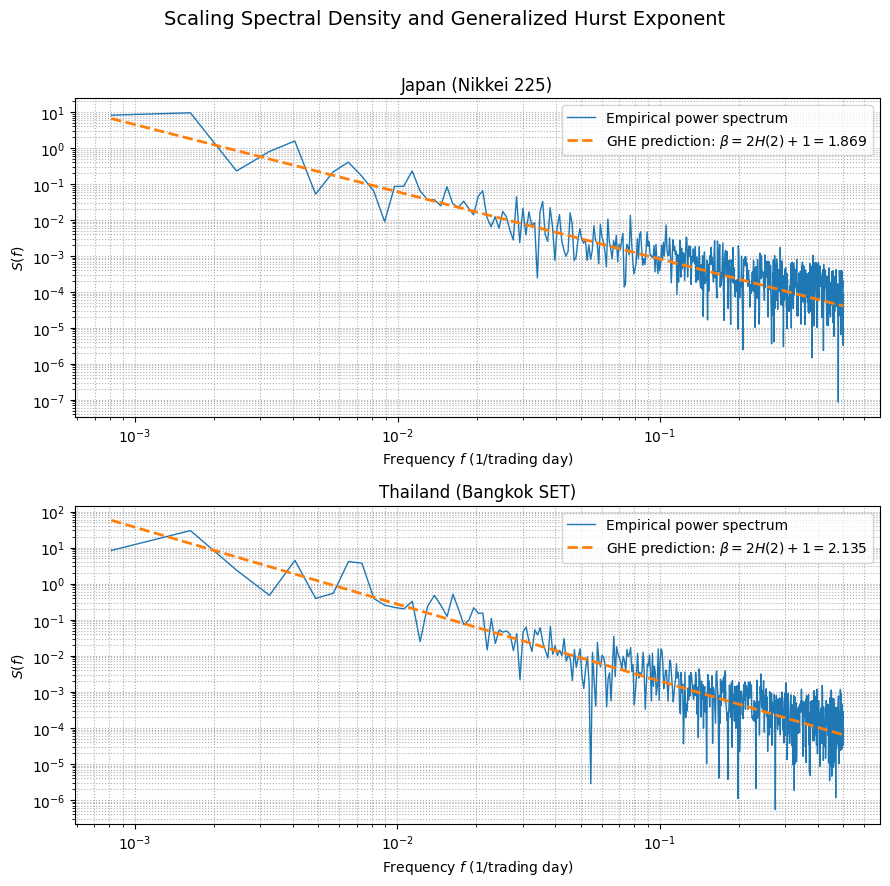

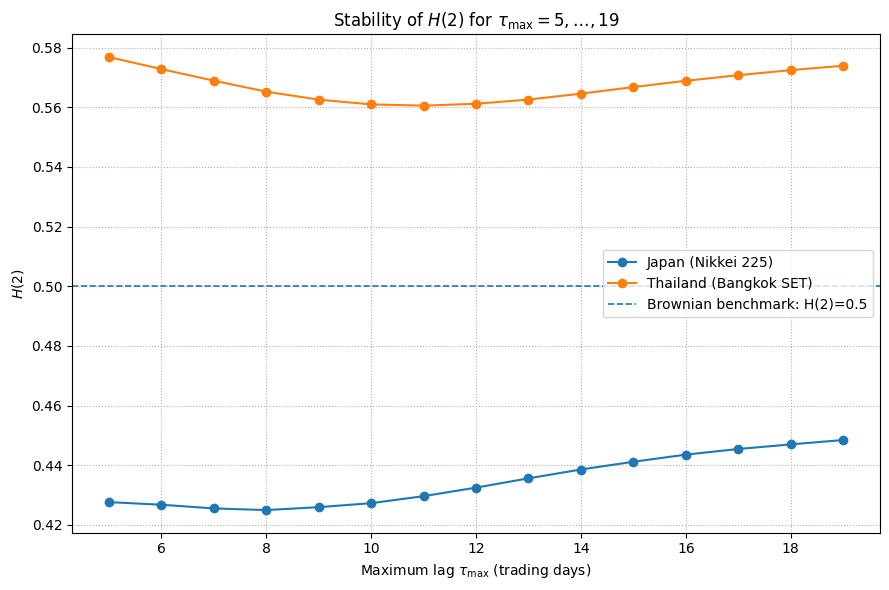


GENERALIZED HURST AND SPECTRAL RESULTS

Japan (Nikkei 225)
------------------------------------------------------------------------------
Ticker                         : ^N225
Number of observations         : 1232
H(2), averaged over tau_max    : 0.4347 ± 0.0086
Mean GHE regression R²         : 0.9990
Predicted beta = 2H(2) + 1     : 1.8694
Direct periodogram beta        : 1.9040
Periodogram regression R²      : 0.7240

Thailand (Bangkok SET)
------------------------------------------------------------------------------
Ticker                         : ^SET.BK
Number of observations         : 1228
H(2), averaged over tau_max    : 0.5673 ± 0.0053
Mean GHE regression R²         : 0.9995
Predicted beta = 2H(2) + 1     : 2.1346
Direct periodogram beta        : 2.1385
Periodogram regression R²      : 0.6620


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from scipy.signal import periodogram
from scipy.stats import linregress


# ============================================================
# Parameters
# ============================================================
tickers = {
    "Japan (Nikkei 225)": "^N225",
    "Thailand (Bangkok SET)": "^SET.BK",
}

start_date = "1997-01-01"
end_date = "2002-01-01"       # yfinance end date is exclusive

q = 2
tau_max_values = range(5, 20)  # 5, 6, ..., 19, as in the paper

# Frequency interval used only to estimate an empirical PSD slope.
# Adjust slightly if the low-frequency region is visibly unsuitable.
psd_fit_min = 0.002
psd_fit_max = 0.100


# ============================================================
# Download one adjusted closing-price series
# ============================================================
def download_prices(ticker, start, end):
    data = yf.download(
        ticker,
        start=start,
        end=end,
        interval="1d",
        auto_adjust=True,
        progress=False,
    )

    if data.empty:
        raise ValueError(f"No data downloaded for {ticker}.")

    prices = data["Close"]

    # Handle recent yfinance MultiIndex output
    if isinstance(prices, pd.DataFrame):
        prices = prices.iloc[:, 0]

    prices = prices.squeeze()
    prices = pd.to_numeric(prices, errors="coerce").dropna()

    if len(prices) < 100:
        raise ValueError(
            f"Insufficient observations for {ticker}: {len(prices)}"
        )

    return prices


# ============================================================
# Remove a linear drift from X(t) = log(P_t)
# ============================================================
def linear_detrend(series):
    x = np.asarray(series, dtype=float)
    t = np.arange(len(x), dtype=float)

    slope, intercept, _, _, _ = linregress(t, x)
    trend = intercept + slope * t

    return x - trend


# ============================================================
# Generalized Hurst exponent H(q)
#
# K_q(tau) =
#     E[|X(t+tau)-X(t)|^q] / E[|X(t)|^q]
#
# K_q(tau) ~ tau^[q H(q)]
# ============================================================
def estimate_hq_for_tau_max(x, q, tau_max):
    denominator = np.mean(np.abs(x) ** q)

    if denominator <= 0 or not np.isfinite(denominator):
        raise ValueError("Invalid normalization denominator.")

    taus = np.arange(1, tau_max + 1, dtype=int)
    kq_values = []

    for tau in taus:
        increments = x[tau:] - x[:-tau]
        numerator = np.mean(np.abs(increments) ** q)
        kq_values.append(numerator / denominator)

    kq_values = np.asarray(kq_values, dtype=float)

    valid = (
        np.isfinite(kq_values)
        & (kq_values > 0)
        & np.isfinite(taus)
    )

    if valid.sum() < 3:
        raise ValueError(
            f"Too few valid scaling points for tau_max={tau_max}."
        )

    regression = linregress(
        np.log(taus[valid]),
        np.log(kq_values[valid]),
    )

    q_hq = regression.slope
    hq = q_hq / q

    return {
        "tau_max": tau_max,
        "Hq": hq,
        "qHq": q_hq,
        "R2": regression.rvalue ** 2,
        "taus": taus,
        "Kq": kq_values,
    }


# ============================================================
# Average H(q) over tau_max = 5,...,19
# ============================================================
def generalized_hurst_exponent(x, q=2, tau_max_values=range(5, 20)):
    estimates = []

    for tau_max in tau_max_values:
        result = estimate_hq_for_tau_max(
            x=x,
            q=q,
            tau_max=tau_max,
        )
        estimates.append(result)

    h_values = np.array(
        [result["Hq"] for result in estimates],
        dtype=float,
    )

    r2_values = np.array(
        [result["R2"] for result in estimates],
        dtype=float,
    )

    return {
        "Hq_mean": float(np.mean(h_values)),
        "Hq_std": float(np.std(h_values, ddof=1)),
        "mean_R2": float(np.mean(r2_values)),
        "estimates": estimates,
    }


# ============================================================
# Power spectral density and empirical spectral slope
#
# S(f) ~ f^(-beta)
# ============================================================
def estimate_power_spectrum(
    x,
    fit_min=0.002,
    fit_max=0.100,
):
    frequencies, psd = periodogram(
        x,
        fs=1.0,              # one observation per trading day
        detrend=False,       # already detrended above
        scaling="density",
        window="boxcar",
    )

    valid = (
        (frequencies > 0)
        & (psd > 0)
        & np.isfinite(frequencies)
        & np.isfinite(psd)
    )

    frequencies = frequencies[valid]
    psd = psd[valid]

    fit_mask = (
        (frequencies >= fit_min)
        & (frequencies <= fit_max)
    )

    if fit_mask.sum() < 5:
        raise ValueError(
            "Too few PSD observations in the selected fitting range."
        )

    regression = linregress(
        np.log(frequencies[fit_mask]),
        np.log(psd[fit_mask]),
    )

    empirical_beta = -regression.slope

    return {
        "frequencies": frequencies,
        "psd": psd,
        "fit_mask": fit_mask,
        "beta_empirical": float(empirical_beta),
        "R2_empirical": float(regression.rvalue ** 2),
    }


# ============================================================
# Scale the theoretical f^(-beta) line to the empirical PSD
#
# This changes only its vertical position, not its slope.
# ============================================================
def scale_theoretical_psd(frequencies, psd, fit_mask, beta):
    f_fit = frequencies[fit_mask]
    psd_fit = psd[fit_mask]

    # log(S) = log(C) - beta*log(f)
    # Therefore log(C) = mean(log(S) + beta*log(f))
    log_c = np.mean(
        np.log(psd_fit) + beta * np.log(f_fit)
    )

    c = np.exp(log_c)
    theoretical_psd = c * frequencies ** (-beta)

    return theoretical_psd


# ============================================================
# Main calculation
# ============================================================
results = {}

for name, ticker in tickers.items():
    prices = download_prices(
        ticker=ticker,
        start=start_date,
        end=end_date,
    )

    log_prices = np.log(prices.values)
    x_detrended = linear_detrend(log_prices)

    ghe = generalized_hurst_exponent(
        x=x_detrended,
        q=q,
        tau_max_values=tau_max_values,
    )

    h2 = ghe["Hq_mean"]
    h2_std = ghe["Hq_std"]

    # Di Matteo relation
    beta_from_hurst = 2 * h2 + 1

    spectrum = estimate_power_spectrum(
        x=x_detrended,
        fit_min=psd_fit_min,
        fit_max=psd_fit_max,
    )

    theoretical_psd = scale_theoretical_psd(
        frequencies=spectrum["frequencies"],
        psd=spectrum["psd"],
        fit_mask=spectrum["fit_mask"],
        beta=beta_from_hurst,
    )

    results[name] = {
        "ticker": ticker,
        "prices": prices,
        "x_detrended": x_detrended,
        "H2": h2,
        "H2_std": h2_std,
        "GHE_mean_R2": ghe["mean_R2"],
        "beta_from_H2": beta_from_hurst,
        "beta_empirical": spectrum["beta_empirical"],
        "PSD_R2": spectrum["R2_empirical"],
        "frequencies": spectrum["frequencies"],
        "psd": spectrum["psd"],
        "theoretical_psd": theoretical_psd,
        "fit_mask": spectrum["fit_mask"],
        "ghe_estimates": ghe["estimates"],
    }


# ============================================================
# Plot 1: PSD and prediction from H(2)
# Similar in purpose to Figure 6 of Di Matteo et al.
# ============================================================
fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(9, 9),
)

for ax, (name, result) in zip(axes, results.items()):
    frequencies = result["frequencies"]
    psd = result["psd"]
    theoretical_psd = result["theoretical_psd"]

    ax.loglog(
        frequencies,
        psd,
        linewidth=1.0,
        label="Empirical power spectrum",
    )

    ax.loglog(
        frequencies,
        theoretical_psd,
        "--",
        linewidth=2.0,
        label=(
            rf"GHE prediction: "
            rf"$\beta=2H(2)+1={result['beta_from_H2']:.3f}$"
        ),
    )

    ax.set_title(name)
    ax.set_xlabel(r"Frequency $f$ (1/trading day)")
    ax.set_ylabel(r"$S(f)$")
    ax.grid(True, which="both", linestyle=":")
    ax.legend()

plt.suptitle(
    "Scaling Spectral Density and Generalized Hurst Exponent",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


# ============================================================
# Plot 2: H(2) stability against tau_max
# ============================================================
plt.figure(figsize=(9, 6))

for name, result in results.items():
    tau_max_array = np.array(
        [
            item["tau_max"]
            for item in result["ghe_estimates"]
        ]
    )

    h2_array = np.array(
        [
            item["Hq"]
            for item in result["ghe_estimates"]
        ]
    )

    plt.plot(
        tau_max_array,
        h2_array,
        marker="o",
        linewidth=1.5,
        label=name,
    )

plt.axhline(
    0.5,
    linestyle="--",
    linewidth=1.2,
    label="Brownian benchmark: H(2)=0.5",
)

plt.xlabel(r"Maximum lag $\tau_{\max}$ (trading days)")
plt.ylabel(r"$H(2)$")
plt.title(r"Stability of $H(2)$ for $\tau_{\max}=5,\ldots,19$")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# Numerical summary
# ============================================================
print("\n" + "=" * 78)
print("GENERALIZED HURST AND SPECTRAL RESULTS")
print("=" * 78)

for name, result in results.items():
    print(f"\n{name}")
    print("-" * 78)
    print(f"Ticker                         : {result['ticker']}")
    print(f"Number of observations         : {len(result['prices'])}")
    print(
        f"H(2), averaged over tau_max    : "
        f"{result['H2']:.4f} ± {result['H2_std']:.4f}"
    )
    print(
        f"Mean GHE regression R²         : "
        f"{result['GHE_mean_R2']:.4f}"
    )
    print(
        f"Predicted beta = 2H(2) + 1     : "
        f"{result['beta_from_H2']:.4f}"
    )
    print(
        f"Direct periodogram beta        : "
        f"{result['beta_empirical']:.4f}"
    )
    print(
        f"Periodogram regression R²      : "
        f"{result['PSD_R2']:.4f}"
    )